In [7]:
import matplotlib.pyplot as plt
import numpy as np
import time
import pandas as pd

In [8]:
#### CONSTANTES FÍSICAS 
## Vamos a trabajar en años

T12 = 5730.0
Lambda = np.log(2)/T12

n0 = 5*10**10 # número de núcleos a tiempo t=0

np.random.seed(123)

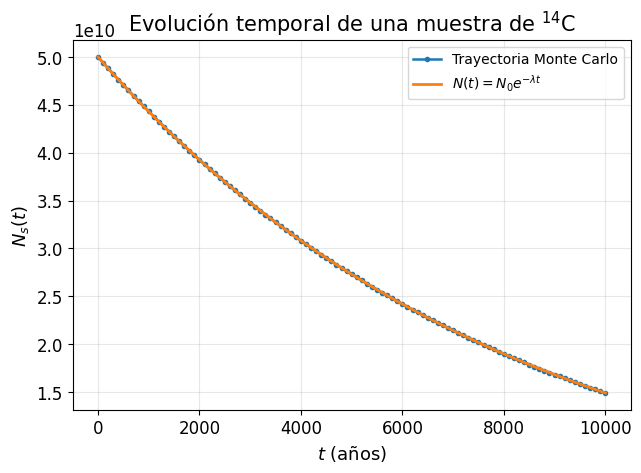

In [9]:
t_real = 1.0e4      # años
dt1 = 100           # años
u1 = int(t_real/dt1)

# Vectores
t_1 = np.arange(u1 + 1) * dt1
Np1 = np.zeros(u1 + 1)

# Condición inicial
N1 = n0
Np1[0] = N1

# Probabilidad de supervivencia en cada intervalo dt
q_step = np.exp(-Lambda * dt1)

# Simulación Monte Carlo: una trayectoria
for j in range(1, u1 + 1):
    N1 = np.random.binomial(N1, q_step)
    Np1[j] = N1

# Curva teórica
Np_teorico_1 = n0 * np.exp(-Lambda * t_1)



#### GRÁFICA DE UNA TRAYECTORIA

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "figure.figsize": (7.2, 4.8),
    "axes.grid": False,
    "lines.linewidth": 1.8
})


plt.plot(t_1, Np1, 'o-', markersize=3, label='Trayectoria Monte Carlo')
plt.plot(t_1, Np_teorico_1, '-', linewidth=2, label=r"$N(t)=N_0e^{-\lambda t}$")

plt.xlabel('$t$ (años)')
plt.ylabel('$N_s(t)$')
plt.title('Evolución temporal de una muestra de $^{14}$C')
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig('E1_trayectoria_C14.png', dpi=300, bbox_inches='tight')
plt.show()

,t_real (años),t_est medio (años),s_t muestral (años),sigma_t analítica (años),error relativo muestral (%),error relativo analítico (%)
0,1000,1000.001,0.014,0.013,0.00136,0.00133
1,5000,4999.998,0.031,0.034,0.00063,0.00067
2,10000,9999.995,0.058,0.057,0.00058,0.00057
3,20000,19999.995,0.118,0.118,0.00059,0.00059
4,25000,24999.981,0.161,0.164,0.00065,0.00065
5,30000,30000.008,0.223,0.224,0.00074,0.00075
6,35000,35000.000,0.312,0.305,0.00089,0.00087
7,40000,40000.040,0.398,0.414,0.00100,0.00103


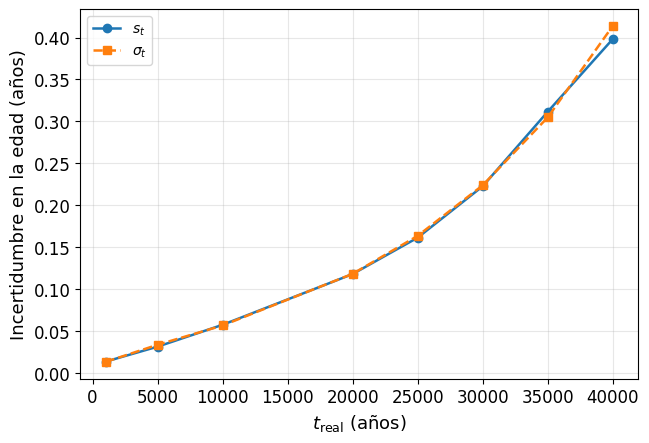

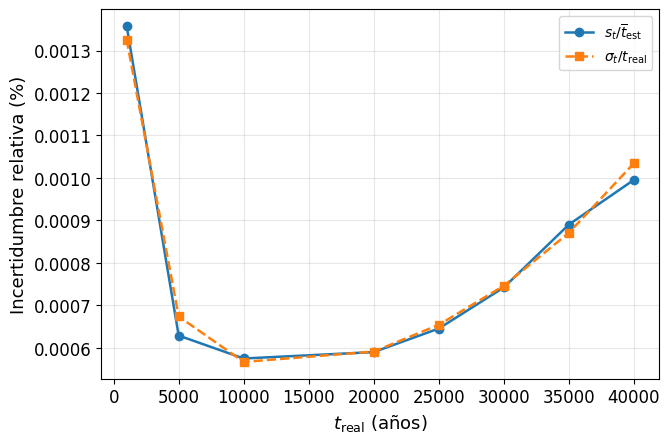

In [10]:
#########################################################
########## ESTIMACIÓN DE EDAD PARA DISTINTOS t_real #####
#########################################################

# Tiempos reales propuestos en la hoja
tiempos_reales = np.array([
    1.0e3, 5.0e3, 1.0e4, 2.0e4,
    2.5e4, 3.0e4, 3.5e4, 4.0e4
])

# Número de simulaciones independientes
M = 500

# Arrays para guardar resultados
media_t_est = np.zeros(len(tiempos_reales))
s_t_muestral = np.zeros(len(tiempos_reales))
sigma_t_analitica = np.zeros(len(tiempos_reales))
error_relativo_muestral = np.zeros(len(tiempos_reales))
error_relativo_analitico = np.zeros(len(tiempos_reales))


for i, t_real in enumerate(tiempos_reales):

    # Probabilidad de supervivencia hasta t_real
    q = np.exp(-Lambda * t_real)

    # M simulaciones independientes del número de núcleos supervivientes
    Np_final = np.random.binomial(n0, q, size=M)

    # Evitar logaritmos de cero, por si en algún caso la muestra queda agotada
    Np_final = Np_final[Np_final > 0]

    # Estimación de la edad en cada simulación
    t_est = -(1 / Lambda) * np.log(Np_final / n0)

    # Media muestral de la edad estimada
    media_t_est[i] = np.mean(t_est)

    # Desviación típica muestral de la edad estimada
    s_t_muestral[i] = np.std(t_est, ddof=1)

    # Incertidumbre analítica
    sigma_t_analitica[i] = (1 / Lambda) * np.sqrt(
        (np.exp(Lambda * t_real) - 1) / n0
    )

    # Incertidumbre relativa muestral
    # Se divide entre la edad estimada media, no entre t_real
    error_relativo_muestral[i] = s_t_muestral[i] / media_t_est[i]

    # Incertidumbre relativa analítica
    # Se divide entre t_real, porque la fórmula analítica se evalúa en t_real
    error_relativo_analitico[i] = sigma_t_analitica[i] / t_real


#########################################################
########## MOSTRAR TABLA ################################
#########################################################


tabla_E2 = pd.DataFrame({
    't_real (años)': tiempos_reales,
    't_est medio (años)': media_t_est,
    's_t muestral (años)': s_t_muestral,
    'sigma_t analítica (años)': sigma_t_analitica,
    'error relativo muestral (%)': 100 * error_relativo_muestral,
    'error relativo analítico (%)': 100 * error_relativo_analitico
})

display(
    tabla_E2.style.format({
        't_real (años)': '{:.0f}',
        't_est medio (años)': '{:.3f}',
        's_t muestral (años)': '{:.3f}',
        'sigma_t analítica (años)': '{:.3f}',
        'error relativo muestral (%)': '{:.5f}',
        'error relativo analítico (%)': '{:.5f}'
    })
)


#########################################################
########## TABLA LÁTEX ##################################
#########################################################

def formato_coma(x, decimales):
    return f"{x:.{decimales}f}".replace(".", ",")

tabla_E2_latex = pd.DataFrame({
    r'$t_{\mathrm{real}}$ (años)': tiempos_reales,
    r'$\overline{t}_{\mathrm{est}}$ (años)': media_t_est,

    # Se reescalan las incertidumbres absolutas:
    # 0.014 años -> 1.4 en unidades de 10^{-2} años
    r'$s_t$ ($10^{-2}$ años)': 1e2 * s_t_muestral,
    r'$\sigma_t$ ($10^{-2}$ años)': 1e2 * sigma_t_analitica,

    # Se reescalan las incertidumbres relativas:
    # 0.00137 % -> 1.37 en unidades de 10^{-3} %
    r'$s_t/\overline{t}_{\mathrm{est}}$ ($10^{-3}\%$)': 1e3 * 100 * error_relativo_muestral,
    r'$\sigma_t/t_{\mathrm{real}}$ ($10^{-3}\%$)': 1e3 * 100 * error_relativo_analitico
})

codigo_latex_E2 = tabla_E2_latex.to_latex(
    index=False,
    escape=False,
    formatters={
        r'$t_{\mathrm{real}}$ (años)': lambda x: formato_coma(x, 0),
        r'$\overline{t}_{\mathrm{est}}$ (años)': lambda x: formato_coma(x, 3),
        r'$s_t$ ($10^{-2}$ años)': lambda x: formato_coma(x, 2),
        r'$\sigma_t$ ($10^{-2}$ años)': lambda x: formato_coma(x, 2),
        r'$s_t/\overline{t}_{\mathrm{est}}$ ($10^{-3}\%$)': lambda x: formato_coma(x, 2),
        r'$\sigma_t/t_{\mathrm{real}}$ ($10^{-3}\%$)': lambda x: formato_coma(x, 2)
    }
)

with open('tabla_E2_estimacion_edad.tex', 'w', encoding='utf-8') as f:
    f.write(codigo_latex_E2)


#########################################################
##### GRÁFICA INCERTIDUMBRES MUESTRAL Y ANALÍTICA ######
#########################################################

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "figure.figsize": (7.2, 4.8),
    "axes.grid": False,
    "lines.linewidth": 1.8
})


plt.plot(
    tiempos_reales,
    s_t_muestral,
    'o-',
    label=r'$s_t$'
)

plt.plot(
    tiempos_reales,
    sigma_t_analitica,
    's--',
    label=r'$\sigma_t$'
)

plt.xlabel(r'$t_{\mathrm{real}}$ (años)')
plt.ylabel(r'Incertidumbre en la edad (años)')

plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig('E2_comparacion_incertidumbre.png', dpi=300, bbox_inches='tight')
plt.show()


#########################################################
# GRÁFICA INCERTIDUMBRES RELATIVA MUESTRAL Y ANALÍTICA #
#########################################################

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "figure.figsize": (7.2, 4.8),
    "axes.grid": False,
    "lines.linewidth": 1.8
})


plt.plot(
    tiempos_reales,
    100 * error_relativo_muestral,
    'o-',
    label=r'$s_t/\overline{t}_{\mathrm{est}}$'
)

plt.plot(
    tiempos_reales,
    100 * error_relativo_analitico,
    's--',
    label=r'$\sigma_t/t_{\mathrm{real}}$'
)

plt.xlabel(r'$t_{\mathrm{real}}$ (años)')
plt.ylabel(r'Incertidumbre relativa (%)')

plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig('E2_comparacion_incertidumbre_relativa.png', dpi=300, bbox_inches='tight')
plt.show()

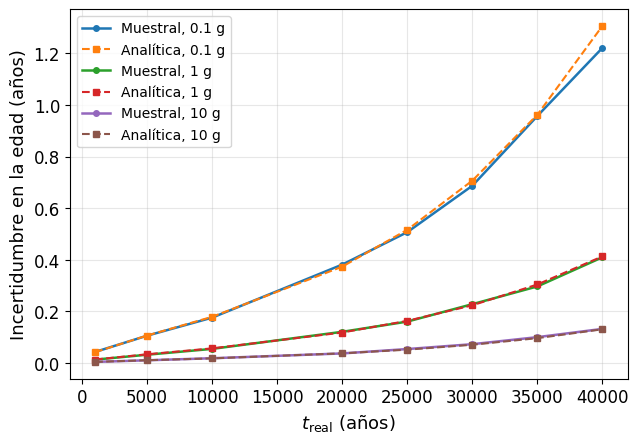

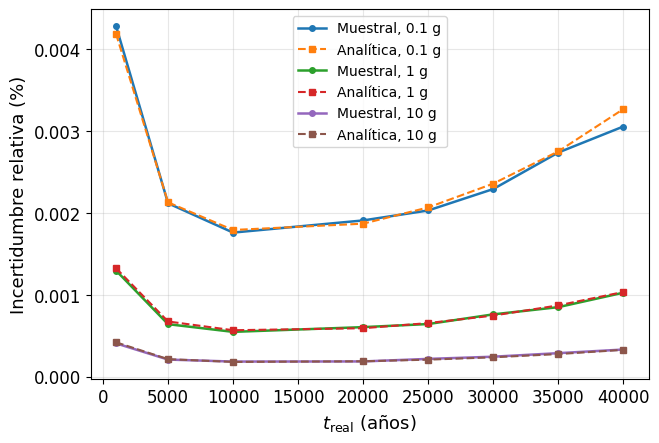

In [11]:
# Tiempos reales para representar
tiempos_E3 =  np.array([1.0e3, 5.0e3, 1.0e4, 2.0e4, 2.5e4, 3.0e4, 3.5e4, 4.0e4])

# Número de simulaciones independientes
M = 500

# Tamaños de muestra en gramos de carbono
masas_C = np.array([0.1, 1.0, 10.0])

# Constantes para calcular N0 a partir de la masa de carbono
NA = 6.022e23          # Número de Avogadro, mol^-1
M_C = 12.0             # Masa molar aproximada del carbono, g/mol
fraccion_C14 = 1.0e-12 # Fracción aproximada de C-14 respecto al carbono total

# Número inicial de núcleos de C-14 para cada masa
N0_muestras = (masas_C / M_C * NA * fraccion_C14).astype(int)

# Matrices para guardar resultados
media_t_est_E3 = np.zeros((len(N0_muestras), len(tiempos_E3)))
sigma_t_muestral_E3 = np.zeros((len(N0_muestras), len(tiempos_E3)))
sigma_t_analitica_E3 = np.zeros((len(N0_muestras), len(tiempos_E3)))

error_relativo_muestral_E3 = np.zeros((len(N0_muestras), len(tiempos_E3)))
error_relativo_analitico_E3 = np.zeros((len(N0_muestras), len(tiempos_E3)))

for i, N0_actual in enumerate(N0_muestras):

    for j, t_real in enumerate(tiempos_E3):

        # Probabilidad de supervivencia hasta t_real
        q = np.exp(-Lambda * t_real)

        # M simulaciones independientes del número final de núcleos supervivientes
        Np_final = np.random.binomial(N0_actual, q, size=M)

        # Evitar log(0), por si en algún caso la muestra queda agotada
        Np_final = Np_final[Np_final > 0]

        # Edad estimada para cada simulación
        t_est = -(1 / Lambda) * np.log(Np_final / N0_actual)

        # Edad media estimada
        media_t_est_E3[i, j] = np.mean(t_est)

        # Incertidumbre muestral
        sigma_t_muestral_E3[i, j] = np.std(t_est, ddof=1)

        # Incertidumbre analítica
        sigma_t_analitica_E3[i, j] = (1 / Lambda) * np.sqrt(
            (np.exp(Lambda * t_real) - 1) / N0_actual
        )

        # Incertidumbre relativa muestral
        error_relativo_muestral_E3[i, j] = sigma_t_muestral_E3[i, j] / media_t_est_E3[i, j]

        # Incertidumbre relativa analítica
        error_relativo_analitico_E3[i, j] = sigma_t_analitica_E3[i, j] / t_real


#########################################################
##### GRÁFICA INCERTIDUMBRE ABSOLUTA ####################
#########################################################

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "figure.figsize": (7.2, 4.8),
    "axes.grid": False,
    "lines.linewidth": 1.8
})


for i, masa in enumerate(masas_C):

    plt.plot(
        tiempos_E3,
        sigma_t_muestral_E3[i],
        'o-',
        markersize=4,
        label=f'Muestral, {masa:g} g'
    )

    plt.plot(
        tiempos_E3,
        sigma_t_analitica_E3[i],
        's--',
        markersize=4,
        linewidth=1.5,
        label=f'Analítica, {masa:g} g'
    )

plt.xlabel('$t_{\\mathrm{real}}$ (años)')
plt.ylabel('Incertidumbre en la edad (años)')

plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig('E3_sigma_t_vs_treal.png', dpi=300, bbox_inches='tight')
plt.show()

#########################################################
##### GRÁFICA INCERTIDUMBRE RELATIVA ####################
#########################################################

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "figure.figsize": (7.2, 4.8),
    "axes.grid": False,
    "lines.linewidth": 1.8
})


for i, masa in enumerate(masas_C):

    plt.plot(
        tiempos_E3,
        100 * error_relativo_muestral_E3[i],
        'o-',
        markersize=4,
        label=f'Muestral, {masa:g} g'
    )

    plt.plot(
        tiempos_E3,
        100 * error_relativo_analitico_E3[i],
        's--',
        markersize=4,
        linewidth=1.5,
        label=f'Analítica, {masa:g} g'
    )

plt.xlabel('$t_{\\mathrm{real}}$ (años)')
plt.ylabel('Incertidumbre relativa (%)')

plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig('E3_sigma_relativa_vs_treal.png', dpi=300, bbox_inches='tight')
plt.show()


In [12]:
#########################################################
##### EDAD APROXIMADA PARA ERROR RELATIVO >= UMBRAL #####
#########################################################

paso_umbral = 100

tiempos_umbral = np.arange(1.0e3, 3.0e5 + paso_umbral, paso_umbral)

umbrales = np.array([0.05, 0.10, 0.20])

tabla_umbral_E3 = []

for i, masa in enumerate(masas_C):

    N0_actual = N0_muestras[i]

    sigma_t_an = (1 / Lambda) * np.sqrt(
        (np.exp(Lambda * tiempos_umbral) - 1) / N0_actual
    )

    error_rel_an = sigma_t_an / tiempos_umbral

    tiempos_para_umbrales = []

    for umbral in umbrales:

        indices = np.where(error_rel_an >= umbral)[0]

        if len(indices) > 0:
            t_umbral = tiempos_umbral[indices[0]]
        else:
            t_umbral = np.nan

        tiempos_para_umbrales.append(t_umbral)

    tabla_umbral_E3.append([
        masa,
        N0_actual,
        tiempos_para_umbrales[0],
        tiempos_para_umbrales[1],
        tiempos_para_umbrales[2]
    ])


#########################################################
########## FUNCIONES DE FORMATO #########################
#########################################################

def formato_masa(x):
    return f"{x:g}"

def formato_entero(x):
    if np.isnan(x):
        return "--"
    return f"{x:.0f}"

def formato_cientifico_latex(x):
    if np.isnan(x):
        return "--"

    exponente = int(np.floor(np.log10(abs(x))))
    coeficiente = x / 10**exponente

    if np.isclose(coeficiente, round(coeficiente)):
        coeficiente_txt = f"{int(round(coeficiente))}"
    else:
        coeficiente_txt = f"{coeficiente:.2g}"

    return rf"${coeficiente_txt}\times 10^{{{exponente}}}$"

def formato_cientifico_notebook(x):
    if np.isnan(x):
        return "--"

    exponente = int(np.floor(np.log10(abs(x))))
    coeficiente = x / 10**exponente

    if np.isclose(coeficiente, round(coeficiente)):
        coeficiente_txt = f"{int(round(coeficiente))}"
    else:
        coeficiente_txt = f"{coeficiente:.2g}"

    return f"{coeficiente_txt}e{exponente}"


#########################################################
########## TABLA UMBRAL  5%, 10%, 20%  ##################
#########################################################

tabla_umbral_E3_notebook = pd.DataFrame({
    'masa de carbono (g)': [
        formato_masa(fila[0]) for fila in tabla_umbral_E3
    ],
    'Núcleos iniciales de C-14': [
        formato_cientifico_notebook(fila[1]) for fila in tabla_umbral_E3
    ],
    'edad para error >= 5% (años)': [
        formato_entero(fila[2]) for fila in tabla_umbral_E3
    ],
    'edad para error >= 10% (años)': [
        formato_entero(fila[3]) for fila in tabla_umbral_E3
    ],
    'edad para error >= 20% (años)': [
        formato_entero(fila[4]) for fila in tabla_umbral_E3
    ]
})

display(tabla_umbral_E3_notebook)


#########################################################
########## TABLA LÁTEX DEL UMBRAL #######################
#########################################################

tabla_umbral_E3_latex = pd.DataFrame({
    r'$m_C$ (g)': [
        formato_masa(fila[0]) for fila in tabla_umbral_E3
    ],
    r'$N_0$': [
        formato_cientifico_latex(fila[1]) for fila in tabla_umbral_E3
    ],
    r'$t_{5\%}$ (años)': [
        formato_entero(fila[2]) for fila in tabla_umbral_E3
    ],
    r'$t_{10\%}$ (años)': [
        formato_entero(fila[3]) for fila in tabla_umbral_E3
    ],
    r'$t_{20\%}$ (años)': [
        formato_entero(fila[4]) for fila in tabla_umbral_E3
    ]
})

codigo_latex_umbral_E3 = tabla_umbral_E3_latex.to_latex(
    index=False,
    escape=False
)

with open('tabla_E3_umbrales_error_relativo.tex', 'w', encoding='utf-8') as f:
    f.write(codigo_latex_umbral_E3)

,masa de carbono (g),Núcleos iniciales de C-14,edad para error >= 5% (años),edad para error >= 10% (años),edad para error >= 20% (años)
0,0.1,5e9,186700,199200,211700
1,1,5e10,207500,219900,232300
2,10,5e11,228100,240400,252700
